In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/financial_sentiment.csv")

df = df.drop_duplicates(subset=["sentence"]).reset_index(drop=True)

print(df.shape)

(2259, 2)


In [2]:
df.head

<bound method NDFrame.head of                                                sentence  label
0     According to Gran , the company has no plans t...      1
1     For the last quarter of 2010 , Componenta 's n...      2
2     In the third quarter of 2010 , net sales incre...      2
3     Operating profit rose to EUR 13.1 mn from EUR ...      2
4     Operating profit totalled EUR 21.1 mn , up fro...      2
...                                                 ...    ...
2254  Operating result for the 12-month period decre...      0
2255  HELSINKI Thomson Financial - Shares in Cargote...      0
2256  LONDON MarketWatch -- Share prices ended lower...      0
2257  Operating profit fell to EUR 35.4 mn from EUR ...      0
2258  Sales in Finland decreased by 10.5 % in Januar...      0

[2259 rows x 2 columns]>

In [3]:
from sklearn.model_selection import train_test_split

train_df , temp_df = train_test_split(df , test_size=0.20 , random_state=42 , stratify=df["label"])

val_df , test_df = train_test_split(temp_df , test_size=0.50 , random_state=42 , stratify=temp_df["label"])

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (1807, 2)
Validation: (226, 2)
Test: (226, 2)


In [4]:
assert set(train_df["sentence"]).isdisjoint(val_df["sentence"])
assert set(train_df["sentence"]).isdisjoint(test_df["sentence"])
assert set(val_df["sentence"]).isdisjoint(test_df["sentence"])

print("Data Leakage Test: PASSED")

Data Leakage Test: PASSED


In [5]:
print("train \n" ,train_df["label"].value_counts(normalize=True).sort_index() * 100 )
print("val \n" ,val_df["label"].value_counts(normalize=True).sort_index() * 100 )
print("test" ,test_df["label"].value_counts(normalize=True).sort_index() * 100 )

train 
 label
0    13.392363
1    61.372441
2    25.235196
Name: proportion, dtype: float64
val 
 label
0    13.274336
1    61.504425
2    25.221239
Name: proportion, dtype: float64
test label
0    13.716814
1    61.061947
2    25.221239
Name: proportion, dtype: float64


In [6]:
from pathlib import Path

splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

split_results = []

for name, data in splits.items():
    assert set(data["label"].unique()) == {0, 1, 2}

    counts = data["label"].value_counts(normalize=True) * 100

    split_results.append({
        "Split": name,
        "Total": len(data),
        "Negative %": round(counts[0], 2),
        "Neutral %": round(counts[1], 2),
        "Positive %": round(counts[2], 2)
    })

split_distribution = pd.DataFrame(split_results)

Path("../reports").mkdir(parents=True, exist_ok=True)

split_distribution.to_csv("../reports/split_distribution.csv", index=False)

display(split_distribution)

,Split,Total,Negative %,Neutral %,Positive %
0,Train,1807,13.39,61.37,25.24
1,Validation,226,13.27,61.50,25.22
2,Test,226,13.72,61.06,25.22


In [7]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
encoded = tokenizer(
    train_df["sentence"].iloc[0] ,
    truncation = True , 
    max_length = 128
    )



print("Input IDs :" , encoded["input_ids"])
print("\nAttention Mask :" , encoded["attention_mask"])
print("\nSpecial Tokens :" , tokenizer.special_tokens_map)
print("\nVocabulary Size :" , tokenizer.vocab_size)
print("\nID'den tokena donusum :" , tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

Input IDs : [101, 16565, 2566, 3745, 2005, 1996, 4284, 2020, 2036, 3020, 2095, 1011, 2006, 1011, 2095, 2012, 1014, 1012, 3943, 7327, 2099, 6431, 1014, 1012, 2676, 1010, 1998, 2682, 3006, 10908, 1997, 1014, 1012, 2654, 7327, 2099, 1012, 102]

Attention Mask : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Special Tokens : {'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}

Vocabulary Size : 30522

ID'den tokena donusum : ['[CLS]', 'earnings', 'per', 'share', 'for', 'the', 'quarter', 'were', 'also', 'higher', 'year', '-', 'on', '-', 'year', 'at', '0', '.', '33', 'eu', '##r', 'versus', '0', '.', '27', ',', 'and', 'above', 'market', 'expectations', 'of', '0', '.', '28', 'eu', '##r', '.', '[SEP]']


In [9]:
from datasets import Dataset, DatasetDict
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer)

train_dataset = Dataset.from_pandas(train_df , preserve_index=False)
val_dataset = Dataset.from_pandas(val_df , preserve_index=False)
test_dataset = Dataset.from_pandas(test_df , preserve_index=False)

dataset = DatasetDict({'train' : train_dataset , 'validation' : val_dataset , 'test' : test_dataset})

In [10]:
def tokenize_function(examples):
    encoded = tokenizer(
        examples["sentence"],
        truncation=True,
        max_length=128,
        padding=False,
        return_token_type_ids=False
    )

    return encoded


tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["sentence"]
)

print(tokenized_dataset)

Map: 100%|██████████| 226/226 [00:00<00:00, 30868.59 examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1807
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 226
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 226
    })
})


In [11]:
examples = [
    tokenized_dataset["train"][0],
    tokenized_dataset["train"][5],
    tokenized_dataset["train"][10]
]

for example in examples:
    print(len(example["input_ids"]))


batch = data_collator(examples)

print(batch)

print("Input IDs:", batch["input_ids"].shape)
print("Attention Mask:", batch["attention_mask"].shape)
print("Labels:", batch["labels"].shape)

38
24
14
{'input_ids': tensor([[  101, 16565,  2566,  3745,  2005,  1996,  4284,  2020,  2036,  3020,
          2095,  1011,  2006,  1011,  2095,  2012,  1014,  1012,  3943,  7327,
          2099,  6431,  1014,  1012,  2676,  1010,  1998,  2682,  3006, 10908,
          1997,  1014,  1012,  2654,  7327,  2099,  1012,   102],
        [  101,  5618,  2005,  1996,  2558,  2001,  7327,  2099,  2321,  1012,
          1020, 24098,  4102,  2000,  7327,  2099,  2403,  1012,  1015, 24098,
          1999,  2289,  1012,   102,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0],
        [  101,  1996,  5211,  2097,  2022,  4276,  3155,  7327,  2099,  2531,
          2213,  2078,  1012,   102,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [12]:
print(batch["attention_mask"].sum(dim=1))
print((batch["attention_mask"] == 0).sum(dim=1))
print((batch["input_ids"] == tokenizer.pad_token_id).nonzero())

tensor([38, 24, 14])
tensor([ 0, 14, 24])
tensor([[ 1, 24],
        [ 1, 25],
        [ 1, 26],
        [ 1, 27],
        [ 1, 28],
        [ 1, 29],
        [ 1, 30],
        [ 1, 31],
        [ 1, 32],
        [ 1, 33],
        [ 1, 34],
        [ 1, 35],
        [ 1, 36],
        [ 1, 37],
        [ 2, 14],
        [ 2, 15],
        [ 2, 16],
        [ 2, 17],
        [ 2, 18],
        [ 2, 19],
        [ 2, 20],
        [ 2, 21],
        [ 2, 22],
        [ 2, 23],
        [ 2, 24],
        [ 2, 25],
        [ 2, 26],
        [ 2, 27],
        [ 2, 28],
        [ 2, 29],
        [ 2, 30],
        [ 2, 31],
        [ 2, 32],
        [ 2, 33],
        [ 2, 34],
        [ 2, 35],
        [ 2, 36],
        [ 2, 37]])


In [13]:
from transformers import AutoModelForSequenceClassification

id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {v: k for k, v in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print(model)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 12248.65it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [14]:
print("Transformer layer sayısı :" , model.config.n_layers)
print("Hidden size"  , model.config.dim)
print("Attention head sayisi :" , model.config.n_heads)





Transformer layer sayısı : 6
Hidden size 768
Attention head sayisi : 12


In [15]:
total_params = sum(p.numel() for p in model.parameters())

print(total_params)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad == True)
print(trainable_params)

first_params = sum(p.numel() for p in model.pre_classifier.parameters())
second_params = sum(p.numel() for p in model.classifier.parameters())

head_params = first_params + second_params
print(head_params)

66955779
66955779
592899


In [16]:
import torch

model.eval()

with torch.no_grad():
    outputs = model(**batch)

logits = outputs.logits
probabilities = torch.softmax(logits, dim=1)
predicted_labels = torch.argmax(probabilities, dim=1)

print("Logits:", logits)
print("Logits Shape:", logits.shape)
print("Loss:", outputs.loss)
print("Softmax Probabilities:", probabilities)
print("Predicted Labels:", predicted_labels)
print("Probability Sums:", probabilities.sum(dim=1))

assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones_like(probabilities[:, 0])
)

print("Probability Sum Test: PASSED")

Logits: tensor([[-0.0927,  0.1482,  0.0338],
        [-0.1173,  0.1185, -0.0276],
        [-0.1397,  0.0813, -0.0330]])
Logits Shape: torch.Size([3, 3])
Loss: tensor(1.0708)
Softmax Probabilities: tensor([[0.2935, 0.3734, 0.3331],
        [0.2976, 0.3768, 0.3256],
        [0.2976, 0.3712, 0.3311]])
Predicted Labels: tensor([1, 1, 1])
Probability Sums: tensor([1.0000, 1.0000, 1.0000])
Probability Sum Test: PASSED


eval_strategy: Her epoch sonunda validation değerlendirmesi yapar.
save_strategy: Her epoch sonunda checkpoint kaydeder.
load_best_model_at_end: Eğitim sonunda en başarılı checkpoint'i yükler.
metric_for_best_model: En başarılı modelin hangi metriğe göre seçileceğini belirler.
greater_is_better: Macro-F1 değerinin yüksek olmasının daha iyi olduğunu belirtir.

In [24]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="../models/distilbert",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    seed=42,
    report_to="none"
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [25]:
import numpy as np

from sklearn.metrics import accuracy_score, f1_score, recall_score , precision_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    recalls = recall_score(
        labels,
        predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "negative_recall": recalls[0],
        "neutral_recall": recalls[1],
        "positive_recall": recalls[2],
        "macro_recall": recalls.mean(),
        "macro_precision": precision_score(
                    labels,
                    predictions,
                    labels=[0, 1, 2],
                    average="macro",
                    zero_division=0
        ),
        
    }

In [26]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer
)

print("Device:", training_args.device)
print("Train Batches:", len(trainer.get_train_dataloader()))
print("Validation Batches:", len(trainer.get_eval_dataloader()))



Device: cuda:0
Train Batches: 113
Validation Batches: 15


In [27]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Negative Recall,Neutral Recall,Positive Recall,Macro Recall,Macro Precision
1,0.639013,0.239885,0.898230,0.863248,0.900000,0.928058,0.824561,0.884206,0.846498
2,0.138751,0.210456,0.929204,0.920412,0.933333,0.913669,0.964912,0.937305,0.910145
3,0.062318,0.118998,0.964602,0.954557,0.966667,0.971223,0.947368,0.961753,0.947795


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  6.16it/s]


In [29]:
training_logs = pd.DataFrame(trainer.state.log_history)
training_logs

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_f1,eval_negative_recall,eval_neutral_recall,...,eval_macro_recall,eval_macro_precision,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.639013,1.024677,1.488525e-05,1.0,113,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,113,0.239885,0.898230,0.863248,0.900000,0.928058,...,0.884206,0.846498,0.1851,1220.791,81.026,NaN,NaN,NaN,NaN,NaN
2,0.138751,0.605184,7.475410e-06,2.0,226,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,226,0.210456,0.929204,0.920412,0.933333,0.913669,...,0.937305,0.910145,0.1800,1255.244,83.313,NaN,NaN,NaN,NaN,NaN
4,0.062318,0.156254,6.557377e-08,3.0,339,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,339,0.118998,0.964602,0.954557,0.966667,0.971223,...,0.961753,0.947795,0.1795,1258.987,83.561,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.0,339,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,18.4974,293.068,18.327,8.264198e+13,0.280027


In [30]:
train_logs = training_logs.loc[
    training_logs["loss"].notna(),
    ["epoch", "loss"]
]

display(train_logs)

val_logs = training_logs.loc[
    training_logs["eval_loss"].notna(),
    ["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]
]

display(val_logs)

,epoch,loss
0,1.0,0.639013
2,2.0,0.138751
4,3.0,0.062318


,epoch,eval_loss,eval_accuracy,eval_macro_f1
1,1.0,0.239885,0.898230,0.863248
3,2.0,0.210456,0.929204,0.920412
5,3.0,0.118998,0.964602,0.954557


In [32]:
training_history = pd.merge(
    train_logs,
    val_logs,
    on="epoch"
)

training_history = training_history.rename(columns={
    "loss": "train_loss",
    "eval_loss": "val_loss",
    "eval_accuracy": "accuracy",
    "eval_macro_f1": "macro_f1"
})

display(training_history)
training_history.to_csv("../reports/training_history.csv", index=False)

,epoch,train_loss,val_loss,accuracy,macro_f1
0,1.0,0.639013,0.239885,0.898230,0.863248
1,2.0,0.138751,0.210456,0.929204,0.920412
2,3.0,0.062318,0.118998,0.964602,0.954557


In [34]:
majority_label = train_df["label"].value_counts().idxmax()

baseline_predictions = np.full(len(val_df), majority_label)

baseline_accuracy = accuracy_score(
    val_df["label"],
    baseline_predictions
)

baseline_f1 = f1_score(
    val_df["label"],
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Macro-F1:", baseline_f1)

Baseline Accuracy: 0.6150442477876106
Baseline Macro-F1: 0.25388127853881276


In [37]:
best_epoch = training_history.loc[
    training_history["macro_f1"].idxmax()
]

baseline_comparison = pd.DataFrame([
    {
        "Model": "Majority Baseline",
        "Accuracy": baseline_accuracy,
        "Macro-F1": baseline_f1
    },
    {
        "Model": "Fine-tuned DistilBERT",
        "Accuracy": best_epoch["accuracy"],
        "Macro-F1": best_epoch["macro_f1"]
    }
])

display(baseline_comparison)

baseline_comparison.to_csv(
    "../reports/baseline_comparison.csv",
    index=False
)

,Model,Accuracy,Macro-F1
0,Majority Baseline,0.615044,0.253881
1,Fine-tuned DistilBERT,0.964602,0.954557


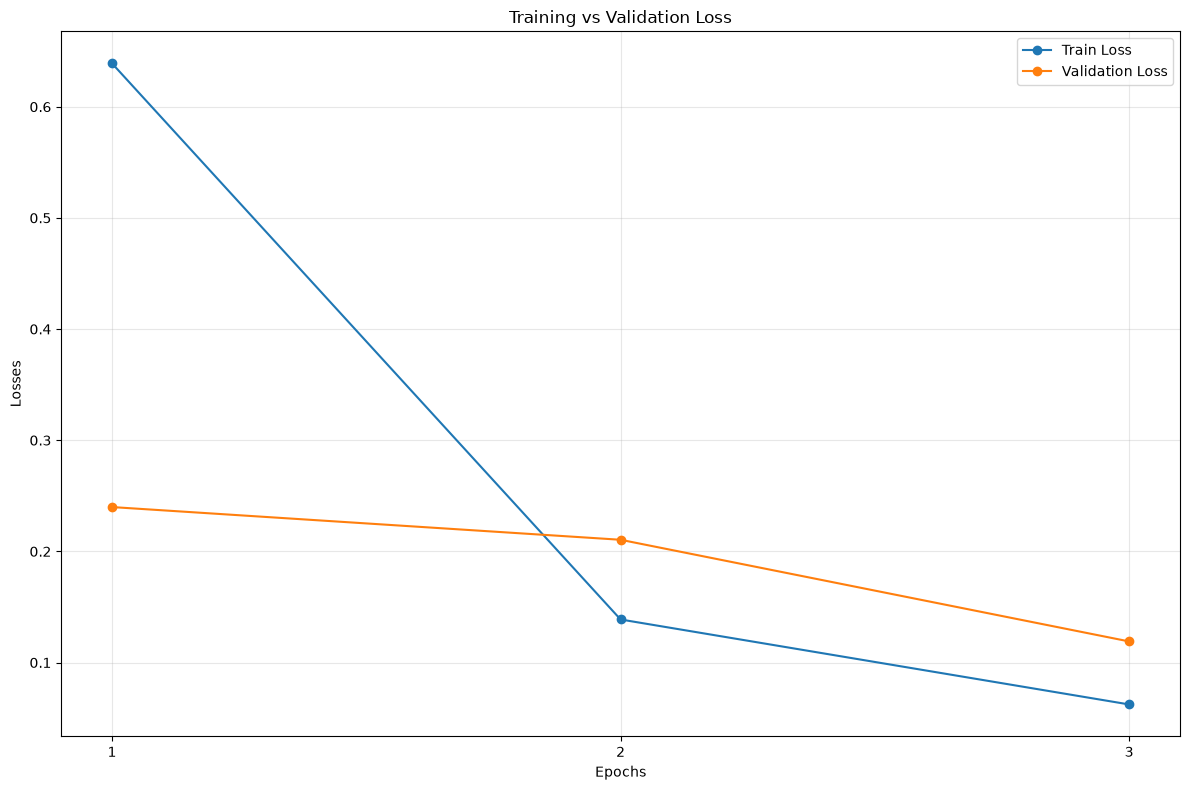

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
x = training_history["epoch"]
y1 = training_history["train_loss"]
y2 = training_history["val_loss"]
plt.plot( x, y1, marker='o'  , label="Train Loss")
plt.plot(x ,y2 , marker="o" , label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()
plt.title("Training vs Validation Loss")
plt.xticks([1, 2, 3])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/training_loss.png", dpi=300)
plt.show()

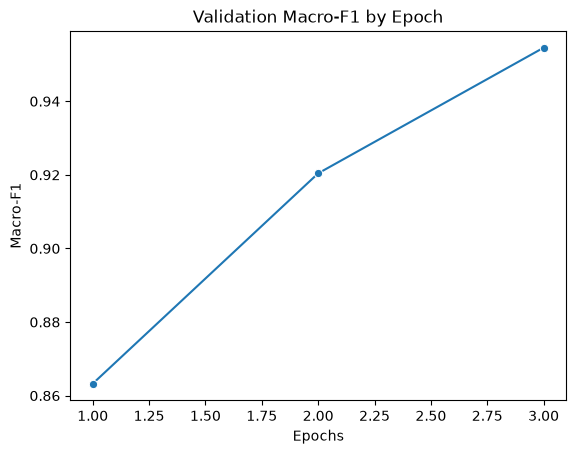

In [61]:
import seaborn as sns

sns.lineplot(data=training_history , x="epoch" , y="macro_f1" , marker="o")
plt.xlabel("Epochs")
plt.ylabel("Macro-F1")
plt.title("Validation Macro-F1 by Epoch")
plt.savefig("../figures/validation_f1.png", dpi=300)
plt.show()

In [62]:
assert len(train_df) + len(val_df) + len(test_df) == 2259
print("Split Size Test: PASSED")


train_sentences = set(train_df["sentence"])
val_sentences = set(val_df["sentence"])
test_sentences = set(test_df["sentence"])

assert train_sentences.isdisjoint(val_sentences)
assert train_sentences.isdisjoint(test_sentences)
assert val_sentences.isdisjoint(test_sentences)
print("Data Leakage Test: PASSED")


for split in [train_df, val_df, test_df]:
    assert set(split["label"].unique()) == {0, 1, 2}

print("Class Coverage Test: PASSED")


for split in tokenized_dataset.values():
    assert all(len(ids) <= 128 for ids in split["input_ids"])

print("Token Length Test: PASSED")


model.eval()
device = next(model.parameters()).device

test_batch = {
    key: value.to(device)
    for key, value in batch.items()
}

with torch.no_grad():
    outputs = model(**test_batch)

logits = outputs.logits
batch_size = test_batch["input_ids"].shape[0]

assert logits.shape == (batch_size, 3)
print("Logits Shape Test: PASSED")


probabilities = torch.softmax(logits, dim=-1)

assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones_like(probabilities[:, 0]),
    atol=1e-6
)

print("Probability Test: PASSED")


assert np.isfinite(training_history["train_loss"]).all()
assert np.isfinite(training_history["val_loss"]).all()
print("Training Loss Test: PASSED")


best_macro_f1 = training_history["macro_f1"].max()

assert best_macro_f1 > baseline_f1, (
    f"DistilBERT: {best_macro_f1}, Baseline: {baseline_f1}"
)

print("Baseline Test: PASSED")

print("\nAll Tests: PASSED")

Split Size Test: PASSED
Data Leakage Test: PASSED
Class Coverage Test: PASSED
Token Length Test: PASSED
Logits Shape Test: PASSED
Probability Test: PASSED
Training Loss Test: PASSED
Baseline Test: PASSED

All Tests: PASSED


In [63]:
trainer.save_model("../models/distilbert_best")
tokenizer.save_pretrained("../models/distilbert_best")

print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best Macro-F1:", trainer.state.best_metric)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.76it/s]

Best checkpoint: ../models/distilbert/checkpoint-339
Best Macro-F1: 0.9545574455693165
